In [1]:
import os

import pandas as pd
import numpy as np
from collections import Counter
from scipy.stats import spearmanr

from ot import sliced_wasserstein_distance
import random
import itertools
import matplotlib.pyplot as plt
import seaborn as sns
from cluster_weather_years.functions import (
    build_df_centroids,
    build_df_random,
)
from cluster_weather_years.constants import (
    BASE_OUTPUT,
    MODELS,
    HYDROLOGICAL_YEARS,
    COUNTRIES,
    SEASONS,
)
from cluster_weather_years.evaluation import qq_univariate_rmse

from sa_settings import MATCH_COUNTRIES

from tqdm.notebook import tqdm

In [2]:
# Config
NUM_CLUSTERS = 30  # hardcode
NUM_CLUSTERS_LARGE_SMALL = 5  # hardcode, 30 years if main one is 5y and vice versa

# RUN_ID_MAIN = "NL_20251024_1320"  # NL, 30 years
# LABEL_RUN_ID_MAIN = "SA, NL 30y"
# RUN_ID_MAIN = "NL_20251112_1638"  # NL, 30y seasonal, incl. residual load
RUN_ID_MAIN = (
    "all_countries_full_vars_20251202_1547"  # full countries, 30y seasonal, incl. rl
)
LABEL_RUN_ID_MAIN = "SA Seasonal, all-countries 30y"
# RUN_ID_MAIN = (
#     "all_countries_full_vars_20251203_1426"  # full countries, 5y seasonal, incl. rl
# )
# LABEL_RUN_ID_MAIN = "SA Seasonal, all-countries 5y"


LABEL_RUN_ID_MAIN_RANDOM = f"Random {NUM_CLUSTERS}y"
# RUN_ID_MAIN = "NL_20251023_0942"  # NL, 5 years
# RUN_ID_MAIN = "NL_20251125_1454"  # NL, 5 yy seasonal, incl. residual load
# LABEL_RUN_ID_MAIN = "SA, NL 5y"
# RUN_ID_alternative = "NL_20251024_1320_5y_subset"  # 5y subsample from 30y sample
# RUN_ID_alternative = "NL_20251111_1601"  # NL, 30y, seasonal_wasserstein
RUN_ID_ALTERNATIVE = "NL_20251112_1638"  # NL, 30y seasonal, incl. residual load
LABEL_RUN_ID_ALTERNATIVE = "SA Seasonal, NL 30y"

# RUN_ID_LARGE_SMALL = "NL_20251024_1320"  # 30 years if main one is 5y and vice versa
RUN_ID_LARGE_SMALL = "NL_20251023_0942"  # 30 years if main one is 5y and vice versa
LABEL_RUN_ID_LARGE_SMALL = "SA, NL 5y subset"
LABEL_RUN_ID_LARGE_SMALL_RANDOM = "Random 5y subset"

FNAME_KMEDOIDS = "centroid_years_load_30yr.csv"  # K-medoids run to compare to
# FNAME_KMEDOIDS = "centroid_years_load.csv"  # K-medoids run to compare to
FNAME_KMEDOIDS_LARGE_SMALL = (
    "centroid_years_load.csv"  # 5yr K-medoids run if main one is 30y and vice versa
)
LABEL_KMEDOIDS = "K-medoids, NL 30y"
# LABEL_KMEDOIDS = "K-medoids, NL 5y"

LABEL_MLZ = "MLZ-25 36y"

seed = 42
random.seed(seed)

# 1. Build dataframes

In [ ]:
# build df
FNAME_PROD_DEMAND = "dataframes/df_prod_demand_daily_all_countries_WRONG_DEMAND.csv"
DF_PROD_DEMAND_FNAME = os.path.join(BASE_OUTPUT, FNAME_PROD_DEMAND)

SA_OUTPUT_DIR = os.path.join(BASE_OUTPUT, "simulated_annealing")

df_daily = pd.read_csv(DF_PROD_DEMAND_FNAME, index_col=0)
df_daily["Date"] = pd.to_datetime(df_daily["Date"])
df_daily = df_daily.query("Hydrological_year > 2014 and Hydrological_year < 2044")

month_to_season = {
    month: season for season, months in SEASONS.items() for month in months
}

df_daily["Season"] = pd.Categorical(
    df_daily["Date"].dt.month.map(month_to_season),
    categories=list(SEASONS.keys()),
    ordered=False,
)

vars_to_match_all = []
for country in MATCH_COUNTRIES:
    vars_to_match_all.extend(
        [
            f"{country}_OFF_prod",
            f"{country}_ON_prod",
            f"{country}_SOLAR_prod",
            f"{country}_Demand",
            f"{country}_Residual_load",
        ]
    )

# remove nan columns (e.g. if country has no offshore production) so that they don't mess with the calculations.
mask_ref = ~np.isnan(df_daily[vars_to_match_all]).any(axis=0)
vars_to_match = list(np.array(vars_to_match_all)[mask_ref.values])

vars_to_plot = vars_to_match + [f"Multi RMSE {country}" for country in MATCH_COUNTRIES]

# settings for random-draws
df_idx = df_daily.set_index(["model", "Hydrological_year"]).sort_index()
keys = df_idx.index.unique().to_numpy()
rng = np.random.default_rng(seed)

In [4]:
df_selections_main = pd.read_csv(
    os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID_MAIN}/results_grid.csv"), index_col=0
)

df_sel_main = df_selections_main.query(
    "optimized_metric == 'wasserstein_seasonal_score'"
).sort_values("best_score", ascending=True)

# alternative one is for comparison
# df_selections_alternative = pd.read_csv(
#     os.path.join(SA_OUTPUT_DIR, f"subsampling/{RUN_ID_alternative}/results_grid.csv"),
#     index_col=0,
# )
# df_sel_alternative_sa = df_selections_alternative.query(
#     "optimized_metric == 'wasserstein_score'"
# ).sort_values("best_score", ascending=True)

df_selections_alternative = pd.read_csv(
    os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID_ALTERNATIVE}/results_grid.csv"),
    index_col=0,
)
df_sel_alternative_sa = df_selections_alternative.query(
    "optimized_metric == 'wasserstein_seasonal_score'"
).sort_values("best_score", ascending=True)

df_selections_large = pd.read_csv(
    os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID_LARGE_SMALL}/results_grid.csv"),
    index_col=0,
)

df_sel_large = df_selections_large.query(
    "optimized_metric == 'wasserstein_score'"
).sort_values("best_score", ascending=True)

centroids_k_medoids_load = pd.read_csv(
    os.path.join(BASE_OUTPUT, f"centroids/{FNAME_KMEDOIDS}"), index_col=0
)
centroids_k_medoids_load_sel = centroids_k_medoids_load[
    ["model", "Hydrological_year"]
].values

In [5]:
mlz_models = ["cmcc_cm2_sr5", "ec_earth3", "mpi_esm_1_2_hr"]
mlz_years = range(2025, 2037)
# combine these models and years into tuples
mlz_modelyears = list(itertools.product(mlz_models, mlz_years))

# 2. Define functions

In [6]:
def build_df_random_large(df_daily, size):
    """
    Build a dataframe with random model-year combinations of arbritary size. To set a benchmark
    """
    model_years = list(itertools.product(MODELS, HYDROLOGICAL_YEARS))
    random_models_years = random.sample(model_years, k=size)

    frames_random = []
    for model_random, year_random in random_models_years:
        df_random = df_daily.query(
            f"model == '{model_random}' and Hydrological_year == {year_random}"
        )
        frames_random.append(df_random)
    return pd.concat(frames_random, ignore_index=True)

In [7]:
def qq_multi_rmse(df_metrics):
    # Add Multi RMSE column which is the average of RMSE for the specified variables
    df_metrics_with_multi = df_metrics.copy()

    # Calculate Multi RMSE for each dataset
    multi_rmse_values = []
    full_rmse_values = []

    for dataset in df_metrics["dataset"].unique():
        dataset_metrics = df_metrics[df_metrics["dataset"] == dataset]
        country_rmse = []
        for country in COUNTRIES:
            multi_rmse_vars = [
                f"{country}_OFF_prod",
                f"{country}_ON_prod",
                f"{country}_SOLAR_prod",
                f"{country}_Demand",
                f"{country}_Residual_load",  # NOTE: JUST ADDED!!
            ]
            multi_rmse = dataset_metrics[
                dataset_metrics["variable"].isin(multi_rmse_vars)
            ]["RMSE"].mean()
            country_rmse.append(multi_rmse)
            multi_rmse_values.append(
                {
                    "dataset": dataset,
                    "variable": f"Multi RMSE {country}",
                    "RMSE": multi_rmse,
                }
            )
        full_rmse_values.append(
            {
                "dataset": dataset,
                "variable": "Multi RMSE Full",
                "RMSE": np.array(country_rmse).mean(),
            }
        )

    # Add Multi RMSE rows to the dataframe
    multi_rmse_df = pd.DataFrame(multi_rmse_values)
    full_rmse_df = pd.DataFrame(full_rmse_values)
    df_metrics_with_multi = pd.concat(
        [df_metrics, multi_rmse_df, full_rmse_df], ignore_index=True
    )
    return df_metrics_with_multi

# 3. Build datasets and calculate metrics

In [8]:
# build datasets to compare

columns = vars_to_match.copy()

# Create datasets dictionary with all available selections from df_sel_combined
datasets = {}

for i in range(len(df_sel_main)):
    datasets[f"{LABEL_RUN_ID_MAIN} {i + 1}"] = build_df_centroids(
        df_daily, eval(df_sel_main.iloc[i]["selected"])
    )

    datasets[f"{LABEL_RUN_ID_LARGE_SMALL} {i + 1}"] = build_df_centroids(
        df_daily, eval(df_sel_large.iloc[i]["selected"])
    )

    datasets[f"{LABEL_RUN_ID_MAIN_RANDOM} {i + 1}"] = build_df_random(
        df_idx, keys, rng, num_random=NUM_CLUSTERS
    )

    datasets[f"{LABEL_RUN_ID_LARGE_SMALL_RANDOM} {i + 1}"] = build_df_random(
        df_idx, keys, rng, num_random=NUM_CLUSTERS_LARGE_SMALL
    )

for i in range(len(df_sel_alternative_sa)):
    datasets[f"{LABEL_RUN_ID_ALTERNATIVE} {i + 1}"] = build_df_centroids(
        df_daily, eval(df_sel_alternative_sa.iloc[i]["selected"])
    )

datasets[f"{LABEL_KMEDOIDS} 1"] = build_df_centroids(
    df_daily, centroids_k_medoids_load_sel, mode="Hydrological_year"
)

datasets["MLZ-25 1"] = build_df_centroids(
    df_daily, mlz_modelyears, mode="Calendar_year"
)

sizes = [
    5,
    10,
    25,
    50,
    90,
    120,
    150,
    174,
]  # 174 is full dataset, because of hydrological years!

for size in sizes:
    datasets[f"Large Random {size}"] = build_df_random_large(df_daily, size)

In [9]:
# calc univariate metrics

df_metrics = qq_univariate_rmse(df_daily, datasets, columns)
# add multivariate metrics
df_metrics = qq_multi_rmse(df_metrics)

# add dataset-type column
df_metrics["dataset_type"] = (
    df_metrics["dataset"].str.replace(r"\s*\d+\s*$", "", regex=True).str.strip()
)

In [10]:
# compute Wasserstein
# TODO: make disjoint
ds_ref = df_daily[vars_to_match].to_numpy()
# Replace NaNs with zeros to avoid issues in distance calculation
ds_ref[np.isnan(ds_ref)] = 0

df_wasserstein = pd.DataFrame(index=datasets.keys(), columns=["Wasserstein_distance"])
for dataset in tqdm(datasets):
    ds_sel = datasets[dataset][vars_to_match].to_numpy()
    ds_sel[np.isnan(ds_sel)] = 0
    df_wasserstein.loc[dataset, "Wasserstein_distance"] = sliced_wasserstein_distance(
        ds_sel, ds_ref, seed=seed, n_projections=50
    )

df_wasserstein["dataset_type"] = (
    df_wasserstein.index.to_series()
    .str.replace(r"\s*\d+\s*$", "", regex=True)
    .str.strip()
)

  0%|          | 0/235 [00:00<?, ?it/s]

# 4. Perform comparison

In [10]:
uni_data_main_vs_random = df_metrics.query(
    "dataset_type in [@LABEL_RUN_ID_MAIN, @LABEL_RUN_ID_MAIN_RANDOM] and variable in @vars_to_plot"
)


## 4.1 Country-level univariate comparison

In [11]:
# only plot top 5 datasets
ds_top5 = [f"{LABEL_RUN_ID_MAIN} {i + 1}" for i in range(5)]
ds_best_nl = ds_top5[0]

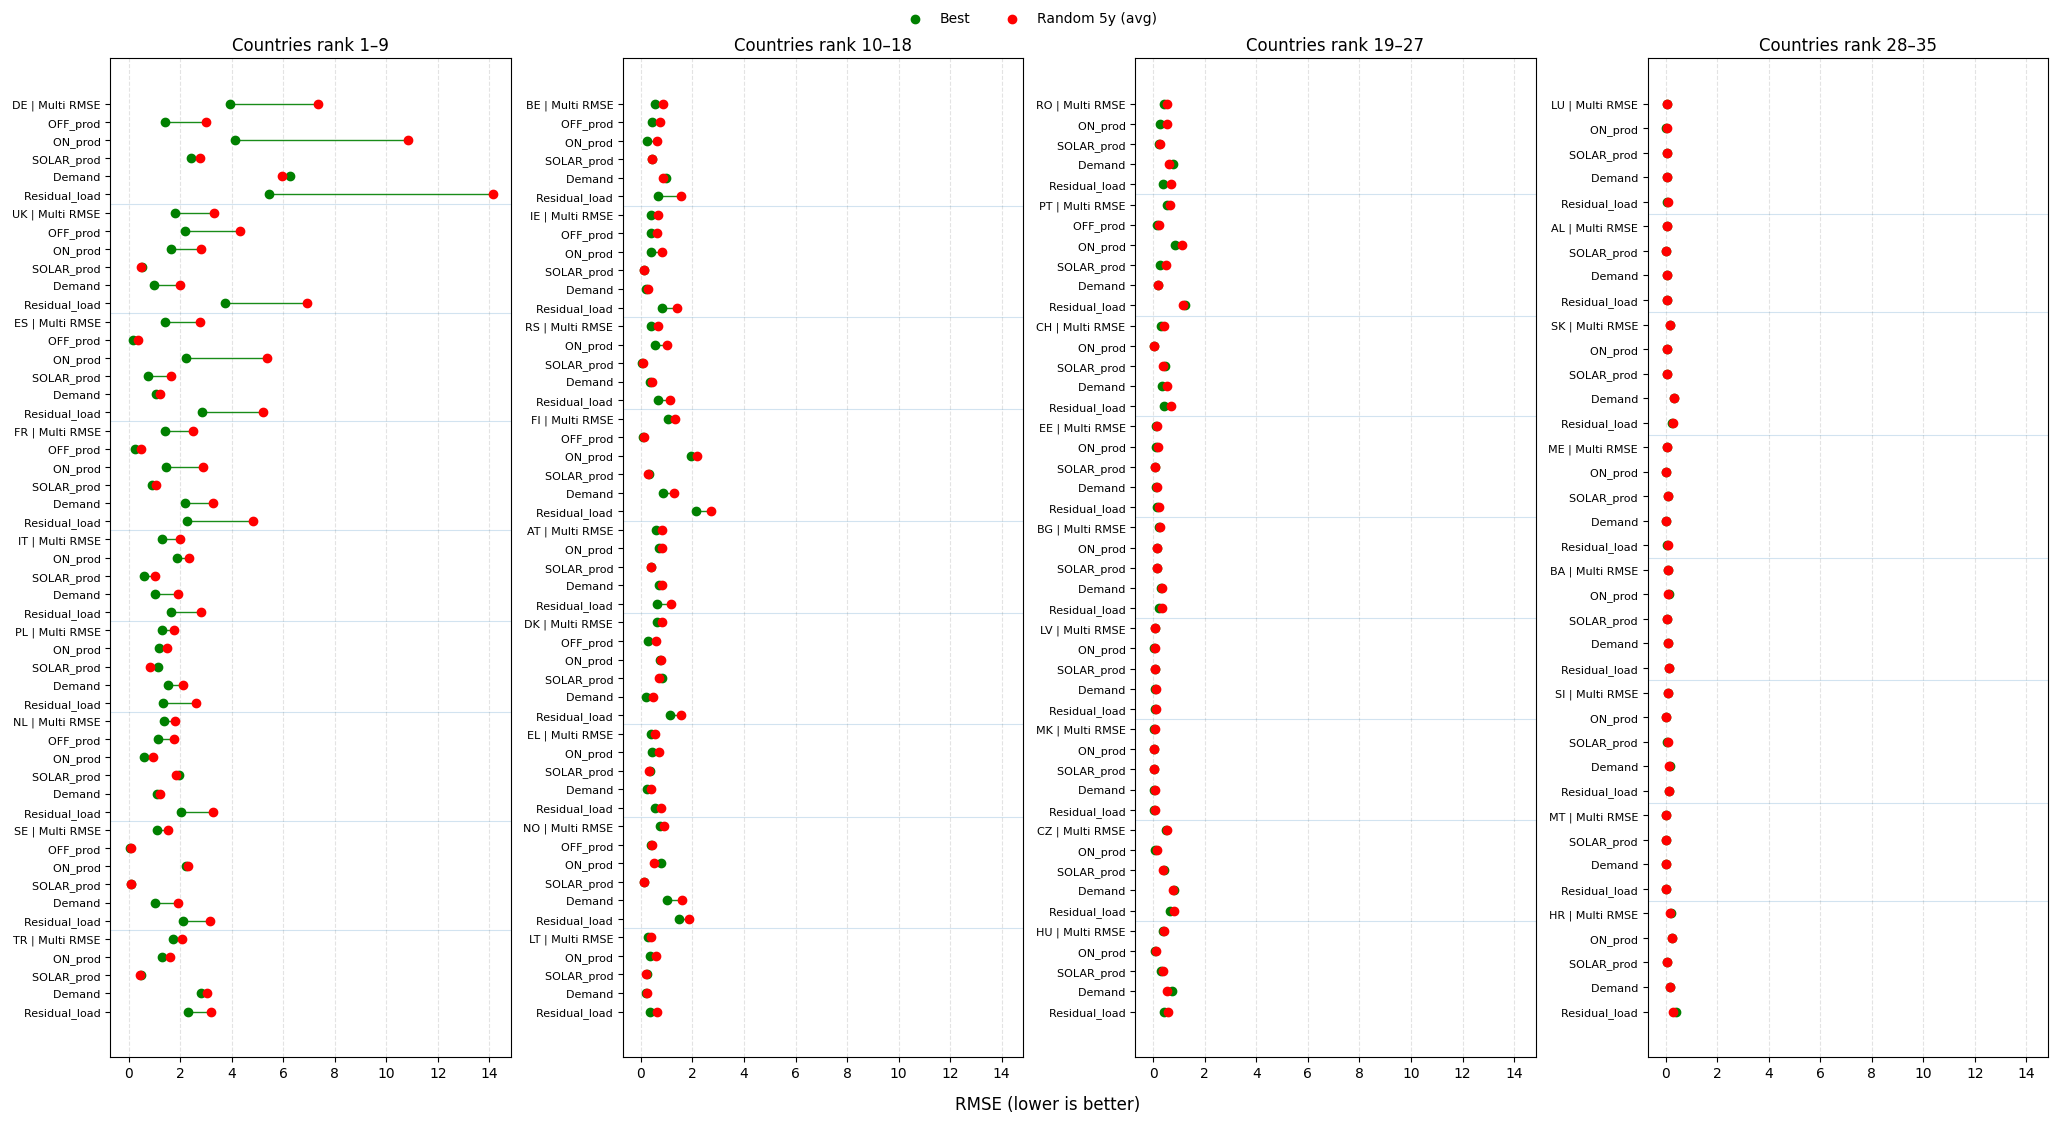

In [12]:
def extract_country(var_name: str) -> str:
    """Extract 2-letter country code from a variable name."""
    if var_name.startswith("Multi RMSE "):
        return var_name.replace("Multi RMSE ", "").strip()
    return var_name.split("_", 1)[0]


def short_label(var_name: str) -> str:
    """Shorten label within-country for y-ticks."""
    if var_name.startswith("Multi RMSE "):
        return "Multi RMSE"
    return var_name.split("_", 1)[1]


def build_country_order(
    vars_to_match: list[str],
    improvement: pd.Series,
) -> list[str]:
    """Order countries by improvement in their Multi RMSE."""
    countries = sorted({extract_country(v) for v in vars_to_match})
    pairs = []
    for c in countries:
        v_multi = f"Multi RMSE {c}"
        if v_multi in improvement.index and pd.notna(improvement.loc[v_multi]):
            pairs.append((c, improvement.loc[v_multi]))
    return [c for c, _ in sorted(pairs, key=lambda x: x[1], reverse=True)]


def build_panel_df(
    panel_countries: list[str],
    vars_to_match: list[str],
    scores_random: pd.Series,
    scores_best: pd.Series,
) -> pd.DataFrame:
    """Build a long dataframe (rows) for a panel of countries."""
    rows = []
    for c in panel_countries:
        v_multi = f"Multi RMSE {c}"
        vars_c = [v for v in vars_to_match if v.startswith(f"{c}_")]

        for v in [v_multi] + vars_c:
            r = scores_random.get(v, np.nan)
            b = scores_best.get(v, np.nan)
            if pd.isna(r) or pd.isna(b):
                continue
            rows.append(
                {
                    "country": c,
                    "variable": v,
                    "label": short_label(v),
                    "random": float(r),
                    "best": float(b),
                }
            )

    df = pd.DataFrame(rows)

    df["improvement"] = df["random"] - df["best"]
    return df


def plot_panel(ax: plt.Axes, df_panel: pd.DataFrame, title: str) -> None:
    """Plot one lollipop panel."""
    if df_panel.empty:
        ax.axis("off")
        return

    y = np.arange(len(df_panel))
    better = df_panel["best"].to_numpy() <= df_panel["random"].to_numpy()
    link_colors = np.where(better, "green", "red")

    x_min = np.minimum(df_panel["best"].to_numpy(), df_panel["random"].to_numpy())
    x_max = np.maximum(df_panel["best"].to_numpy(), df_panel["random"].to_numpy())

    ax.hlines(y, x_min, x_max, linewidth=1, colors=link_colors, alpha=0.9)
    ax.scatter(df_panel["best"], y, zorder=3, c="g", label="Best")
    ax.scatter(df_panel["random"], y, zorder=3, c="r", label="Random 5y (avg)")

    yticks = []
    prev_country = None
    for c, lbl in zip(df_panel["country"], df_panel["label"]):
        if c != prev_country:
            yticks.append(f"{c} | {lbl}")
        else:
            yticks.append(f"    {lbl}")
        prev_country = c

    changes = np.where(
        df_panel["country"].values[:-1] != df_panel["country"].values[1:]
    )[0]
    for idx in changes:
        ax.axhline(idx + 0.5, linewidth=0.8, alpha=0.2)

    ax.set_yticks(y)
    ax.set_yticklabels(yticks)
    ax.invert_yaxis()
    ax.grid(axis="x", linestyle="--", alpha=0.35)
    ax.set_title(title)
    ax.tick_params(axis="y", labelsize=8)


# --- absolute RMSE series ---
scores_random = (
    uni_data_main_vs_random.query(f"dataset_type == 'Random {NUM_CLUSTERS}y'")
    .groupby("variable")["RMSE"]
    .mean()
)

scores_best = (
    uni_data_main_vs_random.query("dataset == @ds_best_nl")
    .groupby("variable")["RMSE"]
    .mean()
)

improvement = scores_random - scores_best
country_order = build_country_order(vars_to_match, improvement)

# --- 4 columns, up to 9 countries per column ---
cols = 4
per_col = 9
panels = [country_order[i : i + per_col] for i in range(0, len(country_order), per_col)]
while len(panels) < cols:
    panels.append([])

panel_dfs = [
    build_panel_df(p, vars_to_match, scores_random, scores_best) for p in panels[:cols]
]

# global x-limits
vals = []
for dfp in panel_dfs:
    if dfp.empty:
        continue
    vals.append(dfp[["best", "random"]].to_numpy().ravel())
vals = np.concatenate(vals) if vals else np.array([0.0, 1.0])
x_lo, x_hi = float(np.nanmin(vals)), float(np.nanmax(vals))
pad = 0.05 * (x_hi - x_lo) if x_hi > x_lo else 0.1 * (x_hi if x_hi else 1.0)

fig_h = max(8, 0.22 * max((len(dfp) for dfp in panel_dfs), default=1))
fig, axes = plt.subplots(1, cols, figsize=(25, fig_h), sharex=True)

for i, (ax, dfp) in enumerate(zip(axes, panel_dfs)):
    start = i * per_col + 1
    end = min((i + 1) * per_col, len(country_order))
    title = f"Countries rank {start}–{end}" if dfp is not None and not dfp.empty else ""
    plot_panel(ax, dfp, title)

fig.supxlabel("RMSE (lower is better)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False)

plt.subplots_adjust(top=0.95, bottom=0.06, wspace=0.28)
plt.show()


## 4.2 Regional level Wasserstein comparison

In [13]:
regions = {
    "Benelux": ["NL", "BE", "LU"],
    "France": ["FR"],
    "Germany": ["DE"],
    "UK_IE": ["UK", "IE"],
    "Iberia": ["ES", "PT"],
    "Central": ["AT", "CH", "IT", "MT"],
    "Nordic_Baltic": ["EE", "LV", "LT", "NO", "SE", "FI"],
    "East": ["PL", "CZ", "SK", "HU", "HR", "SI"],
    "Southeast": ["BA", "RS", "RO", "MK", "AL", "ME", "BG", "TR", "EL"],
}

In [ ]:
vars_base = ["_ON_prod", "_OFF_prod", "_SOLAR_prod", "_Demand", "_Residual_load"]


def build_region_df(df, region):
    """Build df country-group by summing member countries."""
    countries = regions[region]
    df_region = pd.DataFrame()
    for var_suffix in vars_base:
        cols_var = [f"{country}{var_suffix}" for country in countries]
        df_region[f"{region}{var_suffix}"] = df[cols_var].sum(axis=1)
    return df_region


# loop over datasets
# build region dfs
# calc Wasserstein scores (annual, seasonal, worst seasonal)
wass_regional = {}
wass_seasonal_regional = {}
for region in regions.keys():
    ds_ref_region = build_region_df(df_daily, region).to_numpy()
    ds_ref_region[np.isnan(ds_ref_region)] = 0

    wass_regional[region] = []
    for ds in ds_top5:
        df_region = build_region_df(datasets[ds], region)
        ds_region = df_region.to_numpy()
        ds_region[np.isnan(ds_region)] = 0

        wass = sliced_wasserstein_distance(
            ds_region, ds_ref_region, seed=seed, n_projections=50
        )
        wass_regional[region].append(wass)

        for season in SEASONS:
            # mask_season =
            ds_ref_season = ds_ref_region[(df_daily["Season"] == season).to_numpy(), :]
            ds_season = ds_region[(df_region["Season"] == season).to_numpy(), :]

            wass_season = sliced_wasserstein_distance(
                ds_season, ds_ref_season, seed=seed, n_projections=50
            )
            wass_seasonal_regional[(region, season)] = wass_season


pd.DataFrame(wass_regional, index=ds_top5)

AttributeError: 'str' object has no attribute 'to_numpy'

In [53]:
df_region["Season"]

KeyError: 'Season'

In [30]:
pd.DataFrame(wass_regional)

,Benelux,France,Germany,UK_IE,Iberia,Central,Nordic_Baltic,East,Southeast
0,1.753267,1.527096,3.930235,2.515450,2.051330,1.634580,3.478524,2.257045,2.626055
1,2.268794,1.905140,3.800634,2.187176,2.113738,2.371182,3.672518,1.230016,2.768796
2,2.035362,1.528615,4.143037,2.296536,1.881073,2.368127,2.848078,1.804053,2.734249
3,1.635105,1.802776,3.445820,2.063743,2.247754,1.935025,3.061996,1.742281,2.189026
4,2.922401,1.778455,4.404043,2.190522,2.144857,2.096399,3.565401,1.859686,2.259225


In [14]:
# quick check with chatgpt

vars_base = ["_ON_prod", "_OFF_prod", "_SOLAR_prod", "_Demand", "_Residual_load"]


def build_group_matrix(
    df: pd.DataFrame,
    members: list[str],
    vars_base: list[str],
) -> np.ndarray:
    """Build (time, n_vars) matrix for a country-group by summing member countries."""
    df0 = df.fillna(0)

    cols = []
    for suf in vars_base:
        cols.append([f"{c}{suf}" for c in members])

    out = pd.DataFrame(
        {
            suf: df0.reindex(c, axis=1, fill_value=0).sum(axis=1)
            for suf, c in zip(vars_base, cols)
        }
    )
    return out.to_numpy()


def compute_wd_dicts(
    df_daily: pd.DataFrame,
    datasets: dict[str, pd.DataFrame],
    ds_top5: list[str],
    match_countries: list[str],
    vars_base: list[str],
    seed: int,
    num_clusters: int,
    regions: dict[str, list[str]] | None = None,
    aggregate: bool = False,
    n_projections: int = 50,
    n_random: int = 5,
) -> tuple[dict[str, list[float]], dict[str, list[float]], dict[str, float]]:
    """Compute sliced Wasserstein scores for best/top5 and random baselines."""
    if aggregate:
        if regions is None:
            raise ValueError("regions must be provided when aggregate=True")
        groups = {
            r: [c for c in cs if c in match_countries] for r, cs in regions.items()
        }
        groups = {k: v for k, v in groups.items() if len(v) > 0}
    else:
        groups = {c: [c] for c in match_countries}

    random_tag = f"Random {num_clusters}y"

    wd_groups: dict[str, list[float]] = {}
    wd_random_groups_list: dict[str, list[float]] = {}
    wd_random_groups: dict[str, float] = {}

    for group, members in tqdm(groups.items()):
        ref = build_group_matrix(df_daily, members, vars_base)

        wd_groups[group] = []
        for ds_i in ds_top5:
            arr = build_group_matrix(datasets[ds_i], members, vars_base)
            wd_groups[group].append(
                sliced_wasserstein_distance(
                    arr,
                    ref,
                    seed=seed,
                    n_projections=n_projections,
                )
            )

        wd_random_groups_list[group] = []
        for name, df_ds in datasets.items():
            if random_tag not in name:
                continue
            arr = build_group_matrix(df_ds, members, vars_base)
            wd_random_groups_list[group].append(
                sliced_wasserstein_distance(
                    arr,
                    ref,
                    seed=seed,
                    n_projections=n_projections,
                )
            )
            if len(wd_random_groups_list[group]) >= n_random:
                break

        wd_random_groups[group] = float(np.mean(wd_random_groups_list[group]))

    return wd_groups, wd_random_groups_list, wd_random_groups


wd_countries, wd_random_countries_list, wd_random_countries = compute_wd_dicts(
    df_daily=df_daily,
    datasets=datasets,
    ds_top5=ds_top5,
    match_countries=MATCH_COUNTRIES,
    vars_base=vars_base,
    seed=seed,
    num_clusters=NUM_CLUSTERS,
    regions=regions,
    aggregate=True,
)


  0%|          | 0/9 [00:00<?, ?it/s]

In [17]:
sa_top5 = pd.DataFrame.from_dict(wd_countries, orient="index").iloc[:, :5]
sa_top5.columns = [f"SA #{i}" for i in range(1, sa_top5.shape[1] + 1)]
best_dataset = sa_top5["SA #1"]
top5_cols = {c: sa_top5[c] for c in sa_top5.columns}

df_wd_countries = pd.DataFrame(
    {
        "Best dataset": best_dataset,
        **top5_cols,
        f"Random {NUM_CLUSTERS}y (avg)": pd.Series(wd_random_countries),
        "Improvement": pd.Series(wd_random_countries) - best_dataset,
        "Relative improvement (%)": (
            (pd.Series(wd_random_countries) - best_dataset)
            / pd.Series(wd_random_countries)
            * 100
        ),
    }
)

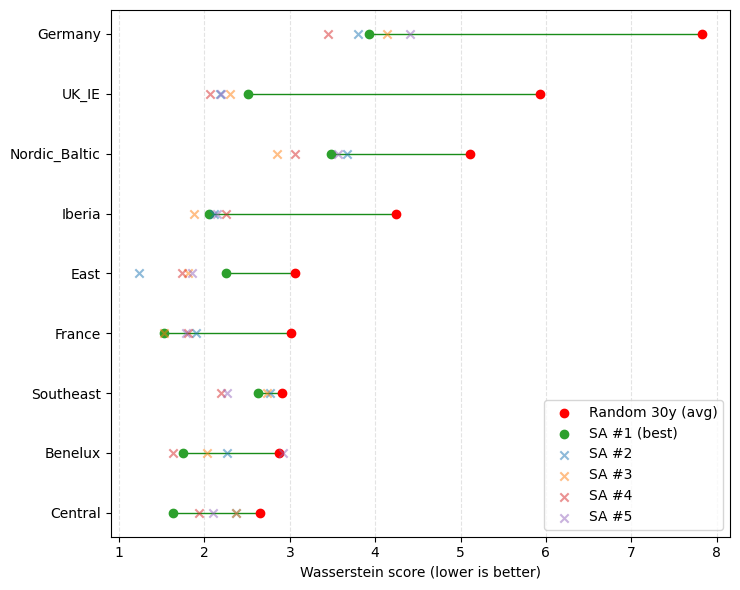

In [16]:
df_plot = df_wd_countries.dropna(
    subset=["Best dataset", f"Random {NUM_CLUSTERS}y (avg)"]
).sort_values(f"Random {NUM_CLUSTERS}y (avg)", ascending=False)

y = np.arange(len(df_plot))
best = df_plot["Best dataset"].to_numpy()
rnd = df_plot[f"Random {NUM_CLUSTERS}y (avg)"].to_numpy()

better = best <= rnd
link_colors = np.where(better, "green", "red")
x_min = np.minimum(best, rnd)
x_max = np.maximum(best, rnd)

fig_h = max(6, 0.3 * len(df_plot))
fig, ax = plt.subplots(figsize=(7.5, fig_h))

ax.hlines(y, x_min, x_max, linewidth=1, colors=link_colors, alpha=0.9)
ax.scatter(rnd, y, c="r", zorder=3, label=f"Random {NUM_CLUSTERS}y (avg)")

colors = ["C2", "C0", "C1", "C3", "C4"]
for col in [f"SA #{i}" for i in range(1, 6) if f"SA #{i}" in df_plot.columns]:
    label = "SA #1 (best)" if col == "SA #1" else col
    ax.scatter(
        df_plot[col].to_numpy(),
        y,
        marker="o" if col == "SA #1" else "x",
        c=colors[int(col.split("#")[1]) - 1],
        zorder=3,
        alpha=1 if col == "SA #1" else 0.5,
        label=label,
    )

ax.set_yticks(y)
ax.set_yticklabels(df_plot.index.astype(str))
ax.invert_yaxis()

ax.set_xlabel("Wasserstein score (lower is better)")
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

## 4.4 Seasonal-comparison

In [19]:
df_wasserstein_seasonal = pd.DataFrame(
    index=datasets.keys(), columns=["Wass_summer", "Wass_winter"]
)
ds_ref_summer = df_daily.query("Date.dt.month in @SEASONS['Summer']")[
    vars_to_match
].to_numpy()
ds_ref_summer[np.isnan(ds_ref_summer)] = 0
ds_ref_winter = df_daily.query("Date.dt.month in @SEASONS['Winter']")[
    vars_to_match
].to_numpy()
ds_ref_winter[np.isnan(ds_ref_winter)] = 0

for dataset in tqdm(datasets):
    ds_sel_summer = (
        datasets[dataset]
        .query("Date.dt.month in @SEASONS['Summer']")[vars_to_match]
        .to_numpy()
    )
    ds_sel_summer[np.isnan(ds_sel_summer)] = 0
    ds_sel_winter = (
        datasets[dataset]
        .query("Date.dt.month in @SEASONS['Winter']")[vars_to_match]
        .to_numpy()
    )
    ds_sel_winter[np.isnan(ds_sel_winter)] = 0
    df_wasserstein_seasonal.loc[dataset, "Wass_summer"] = sliced_wasserstein_distance(
        ds_sel_summer, ds_ref_summer, seed=seed, n_projections=50
    )
    df_wasserstein_seasonal.loc[dataset, "Wass_winter"] = sliced_wasserstein_distance(
        ds_sel_winter, ds_ref_winter, seed=seed, n_projections=50
    )
df_wasserstein_seasonal["dataset_type"] = (
    df_wasserstein_seasonal.index.to_series()
    .astype(str)
    .str.replace(r"\s*\d+\s*$", "", regex=True)
    .str.strip()
)

  0%|          | 0/67 [00:00<?, ?it/s]

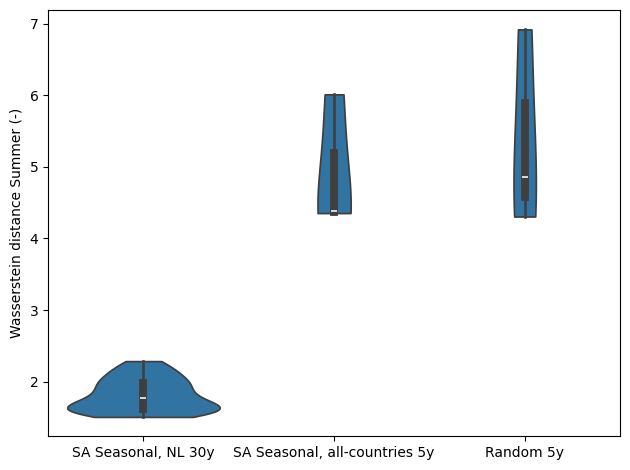

In [20]:
df_wass_seasonal_plot = df_wasserstein_seasonal.query(
    "dataset_type in [@LABEL_RUN_ID_MAIN, @LABEL_RUN_ID_ALTERNATIVE, @LABEL_RUN_ID_MAIN_RANDOM]"
)
order = (
    df_wass_seasonal_plot.groupby("dataset_type")["Wass_summer"]
    .median()
    .sort_values()
    .index.tolist()
)

ax = sns.violinplot(
    data=df_wass_seasonal_plot,
    x="dataset_type",
    y="Wass_summer",
    order=order,
    inner="box",
    cut=0,
)
ax.set_ylabel("Wasserstein distance Summer (-)")
ax.set_xlabel(None)
plt.xticks()
plt.tight_layout()

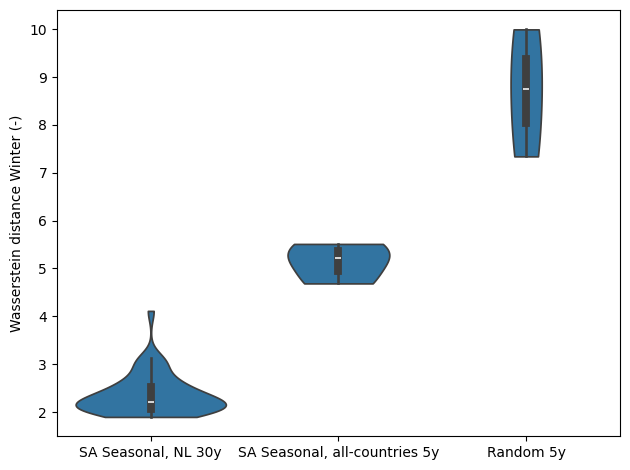

In [21]:
order = (
    df_wass_seasonal_plot.groupby("dataset_type")["Wass_winter"]
    .median()
    .sort_values()
    .index.tolist()
)

ax = sns.violinplot(
    data=df_wass_seasonal_plot,
    x="dataset_type",
    y="Wass_winter",
    order=order,
    inner="box",
    cut=0,
)
ax.set_ylabel("Wasserstein distance Winter (-)")
ax.set_xlabel(None)
plt.xticks()
plt.tight_layout()

In [22]:
df_worst_season = (
    df_wass_seasonal_plot[["Wass_summer", "Wass_winter"]]
    .max(axis=1)
    .to_frame(name="Wass_worst_season")
)
df_worst_season["dataset_type"] = df_wass_seasonal_plot["dataset_type"]

([0, 1, 2],
 [Text(0, 0, 'SA Seasonal, NL 30y'),
  Text(1, 0, 'SA Seasonal, all-countries 5y'),
  Text(2, 0, 'Random 5y')])

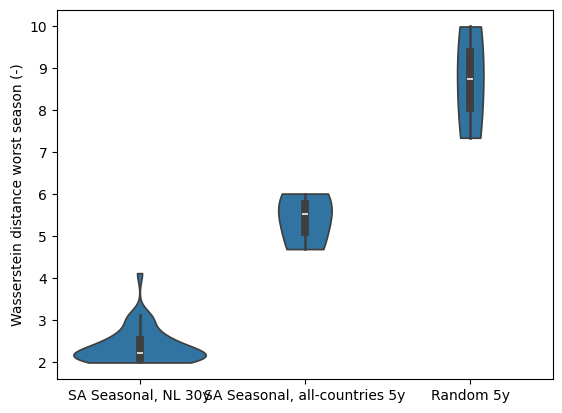

In [23]:
ax = sns.violinplot(
    data=df_worst_season,
    x="dataset_type",
    y="Wass_worst_season",
    order=order,
    inner="box",
    cut=0,
)
ax.set_ylabel("Wasserstein distance worst season (-)")
ax.set_xlabel(None)
plt.xticks()

Text(0, 0.5, 'Wasserstein Winter (-)')

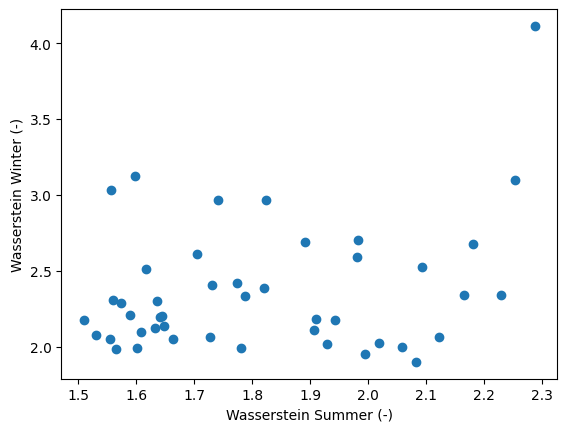

In [24]:
df_wass_alternative = df_wasserstein_seasonal[
    df_wasserstein_seasonal["dataset_type"] == LABEL_RUN_ID_ALTERNATIVE
]
plt.scatter(
    df_wass_alternative["Wass_summer"],
    df_wass_alternative["Wass_winter"],
)
plt.xlabel("Wasserstein Summer (-)")
plt.ylabel("Wasserstein Winter (-)")

## 4.5 Look at impact of subset size

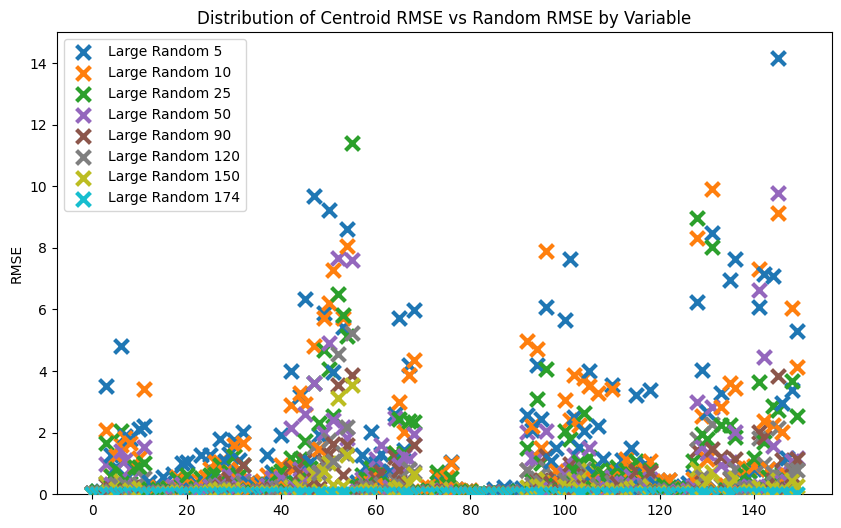

In [ ]:
# calculate large random scores

# Get centroid RMSE values for each variable
random_metrics_lr = df_metrics.query("dataset.str.contains('Large Random')")

# Create violin plot of centroid RMSE values
fig, ax = plt.subplots(figsize=(10, 6))

colors = plt.cm.tab10(np.linspace(0, 1, len(sizes)))
for i, var in enumerate(vars_to_match):
    for j, size in enumerate(sizes):
        rmse = random_metrics_lr.query(
            f"dataset == 'Large Random {size}' and variable == @var"
        )["RMSE"].item()
        ax.scatter(
            i,
            rmse,
            marker="x",
            s=100,
            linewidth=3,
            label=f"Large Random {size}" if i == 0 else "",
            zorder=10,
            color=colors[j],
        )

ax.set_ylim(0, 15)
ax.set_title("Distribution of Centroid RMSE vs Random RMSE by Variable")
ax.set_ylabel("RMSE")
ax.legend()

In [26]:
# k-medoids large-small
centroids_k_medoids_load_large_small = pd.read_csv(
    os.path.join(BASE_OUTPUT, f"centroids/{FNAME_KMEDOIDS_LARGE_SMALL}"), index_col=0
)
centroids_k_medoids_load_large_small_sel = centroids_k_medoids_load_large_small[
    ["model", "Hydrological_year"]
].values

df_k_medoids_large_small = build_df_centroids(
    df_daily, centroids_k_medoids_load_large_small_sel, mode="Hydrological_year"
)[vars_to_match].to_numpy()

df_k_medoids_large_small[np.isnan(df_k_medoids_large_small)] = 0

wass_k_medoids_large_small = sliced_wasserstein_distance(
    df_k_medoids_large_small,
    ds_ref,
    seed=seed,
    n_projections=50,
)

Text(0, 0.5, 'Wasserstein distance (-)')

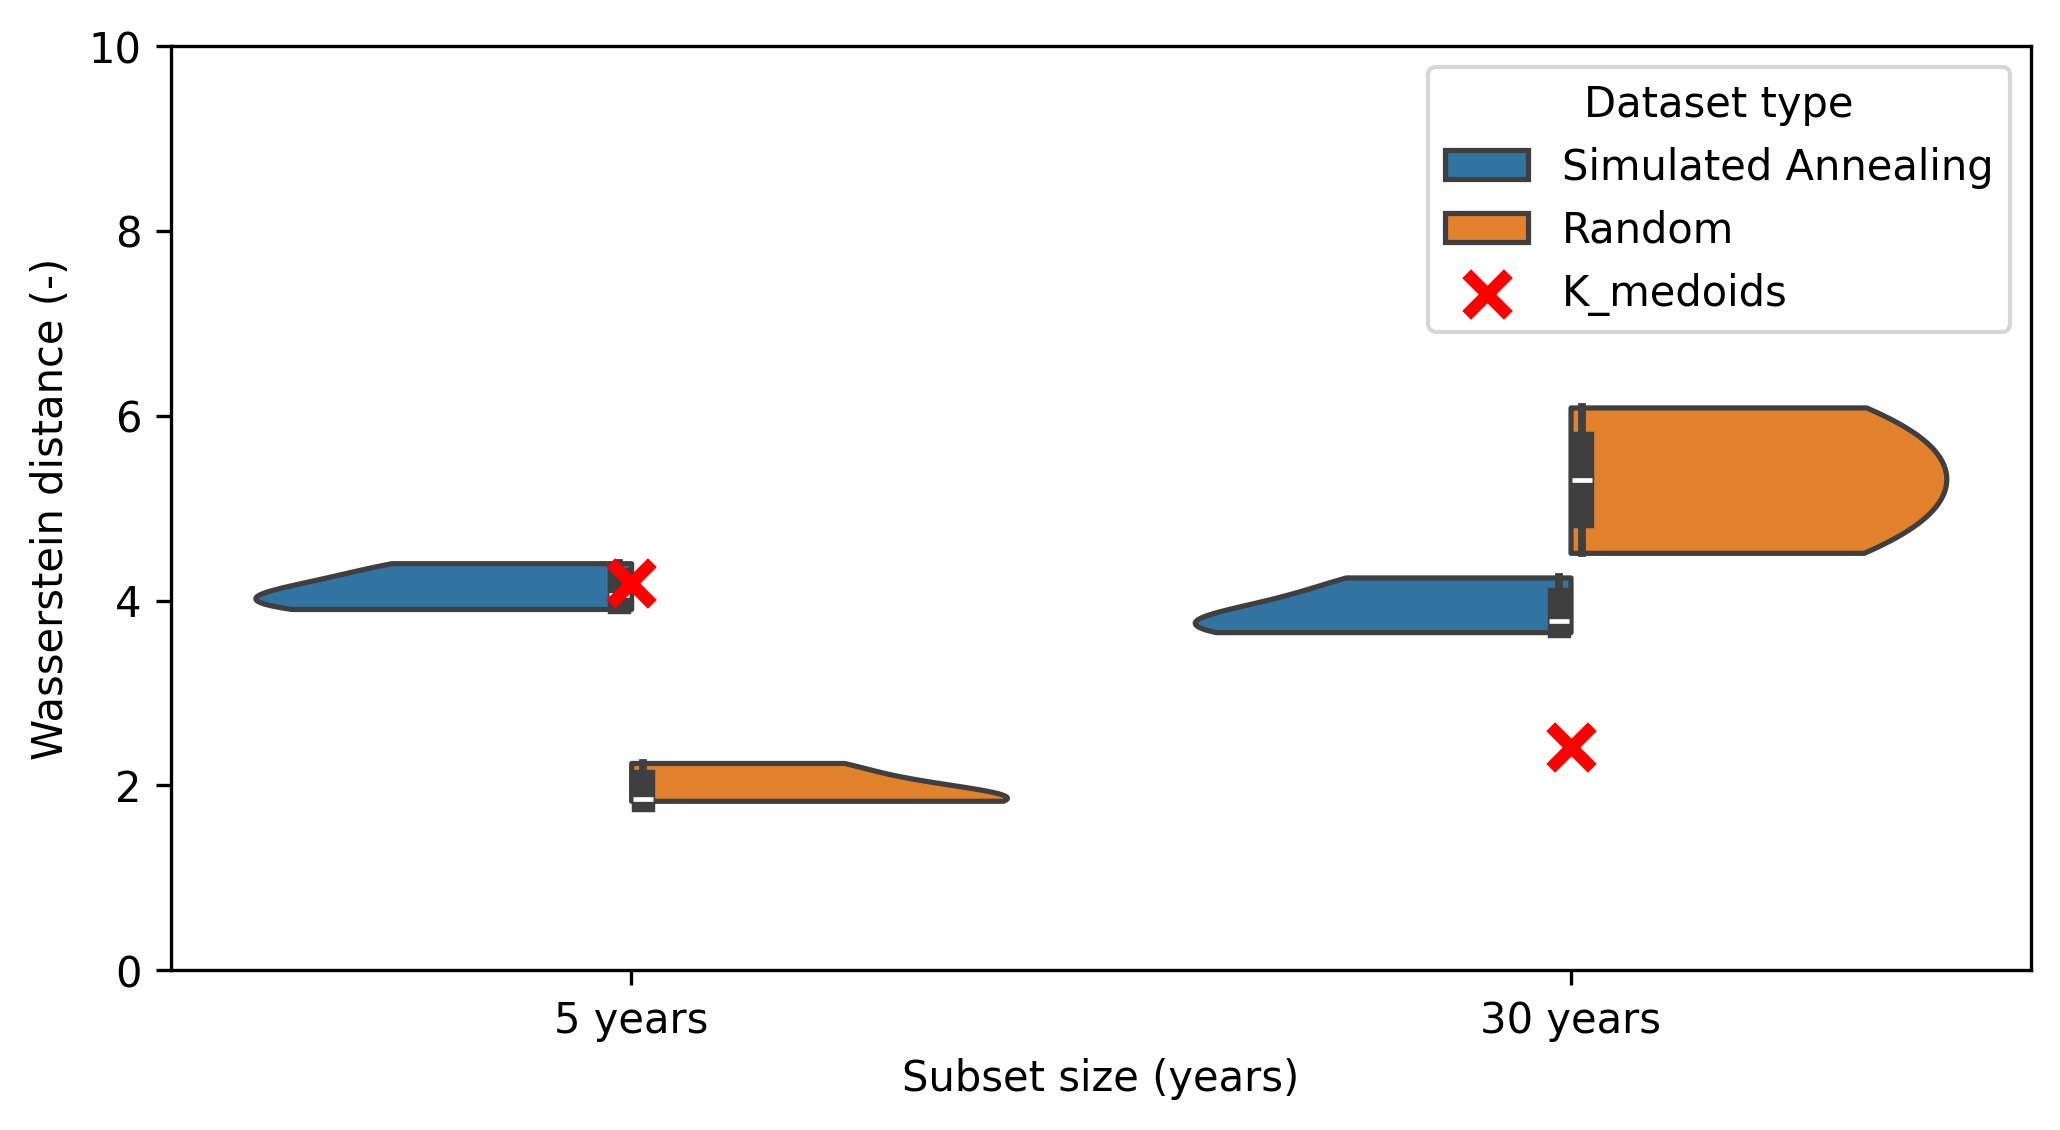

In [27]:
wass_large_small = df_wasserstein.query(
    "dataset_type in [@LABEL_RUN_ID_LARGE_SMALL_RANDOM, @LABEL_RUN_ID_LARGE_SMALL]"
)

# main SA vs large/small SA
fig, ax = plt.subplots(figsize=(8, 4), dpi=300)

sns.violinplot(
    data=wass_large_small,
    hue="dataset_type",
    x=0,
    y="Wasserstein_distance",
    ax=ax,
    cut=0,
    split=True,
)

ax.scatter(
    0,
    wass_k_medoids_large_small,
    marker="x",
    color="red",
    s=100,
    linewidth=3,
    label="K_medoids",
    zorder=10,
)

handles, labels = ax.get_legend_handles_labels()
labels = ["Simulated Annealing", "Random", "K_medoids"]

sns.violinplot(
    data=wass_main_vs_random,
    hue="dataset_type",
    x=1,
    y="Wasserstein_distance",
    ax=ax,
    cut=0,
    split=True,
)

ax.scatter(
    1,
    df_wasserstein.query("dataset_type == @LABEL_KMEDOIDS")[
        "Wasserstein_distance"
    ].values[0],
    marker="x",
    color="red",
    s=100,
    linewidth=3,
    label="K_medoids",
    zorder=10,
)


# Use only the legend from the first plot
ax.legend(handles, labels, title="Dataset type")

ax.set_ylim(0, 10)
ax.set_xticks([0, 1], ["5 years", "30 years"])
ax.set_xlabel("Subset size (years)")
ax.set_ylabel("Wasserstein distance (-)")

## 4.6 Individual years also representative?

In [28]:
chosen_modelyears = []
for i in range(len(df_sel_main)):
    chosen_modelyears.extend(eval(df_sel_main["selected"][i]))

In [29]:
# calc wasserstein per modelyear, look for correlation with number of times chosen
modelyear_wass = {}
for model in MODELS:
    for year in tqdm(HYDROLOGICAL_YEARS):
        ds_modelyear = df_daily.query(
            f"model == '{model}' and Hydrological_year == {year}"
        )[vars_to_match].to_numpy()
        ds_modelyear[np.isnan(ds_modelyear)] = 0
        wass = sliced_wasserstein_distance(
            ds_modelyear, ds_ref, seed=seed, n_projections=50
        )
        modelyear_wass[(model, year)] = wass

# 45*30 = 1350
# 180 modelyears in total, so on average each modelyear is chosen 7.5 times
modelyear_count = Counter(chosen_modelyears)

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
rows = []
for model in MODELS:
    for year in HYDROLOGICAL_YEARS:
        rows.append(
            {
                "model": model,
                "year": year,
                "count": int(modelyear_count.get((model, year), 0)),
                "wass": float(modelyear_wass.get((model, year), np.nan)),
            }
        )

df_mw = pd.DataFrame(rows).dropna(subset=["wass"])

# Correlations
rho, p_rho = spearmanr(df_mw["count"], df_mw["wass"])

print(f"Spearman rho = {rho:.3f}, p = {p_rho:.3e}")

Spearman rho = -0.112, p = 1.423e-01


(0.0, 15.65)

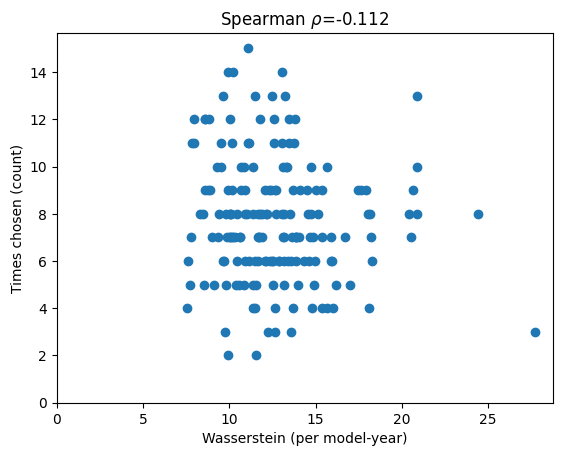

In [ ]:
plt.scatter(df_mw["wass"], df_mw["count"])
plt.title(f"Spearman $\\rho$={rho:.3f}")
plt.xlabel("Wasserstein (per model-year)")
plt.ylabel("Times chosen (count)")
plt.xlim(0, None)
plt.ylim(0, None)